<a href="https://colab.research.google.com/github/rounakjha52-cmd/ai-in-cybersecurity-assignment-3/blob/main/ENSP355_Lab3_Rounak_Jha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

uploaded = files.upload()  # Select simple_cyber_activity.csv
csv_file = next((name for name in uploaded if name.lower().endswith('.csv')), None)

if csv_file is None:
    raise FileNotFoundError("Please upload simple_cyber_activity.csv")

df = pd.read_csv(csv_file)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", list(df.columns))

Saving simple_cyber_activity.csv to simple_cyber_activity (1).csv
Dataset shape: (100, 6)


,record_id,failed_logins,login_hour,new_device,data_transfer_mb,label
0,1,4,1,0,164.9,1
1,2,3,3,1,250.6,1
2,3,3,10,0,145.1,0
3,4,2,11,0,397.8,0
4,5,1,3,0,409.3,0



Columns: ['record_id', 'failed_logins', 'login_hour', 'new_device', 'data_transfer_mb', 'label']


## Q1. CNN, RNN/LSTM and GAN Concept Matching (5 Marks)

**Aim:** Connect three deep-learning families with suitable cyber-security data and applications.

| Model | Suitable data | Cyber-security example |
|---|---|---|
| CNN | Images / grid-like data | Malware image classification |
| RNN / LSTM | Sequences / logs / time series | Sequential intrusion or authentication-log analysis |
| GAN | Synthetic-data generation | Generate controlled synthetic attack samples |
| Dense Network | Small numeric feature table | Normal/Attack classification in this lab |

**Why is a dense network used in this practical?**  
The dataset contains four numeric input features. A dense neural network is suitable for learning relationships among these structured numeric features and classifying each record as Normal or Attack.

## Q2. Dataset Preparation, Split and Normalization (5 Marks)

**Aim:** Load the prepared dataset, separate inputs and label, split the data, and standardize numeric features.

The binary label uses **0 = Normal** and **1 = Attack**. `StandardScaler` puts features on a comparable numeric scale. The scaler is fitted only on the training data and then used to transform the training, testing, and new-record data.

In [2]:
# Select the four numeric features and the target label
features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'data_transfer_mb'
]

required_columns = features + ['label']
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

X = df[features]
y = df['label']

print("Class counts (0 = Normal, 1 = Attack):")
print(y.value_counts().sort_index().rename(index={0: "Normal (0)", 1: "Attack (1)"}))

# 75% training and 25% testing split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Fit scaler on training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Class counts (0 = Normal, 1 = Attack):
label
Normal (0)    75
Attack (1)    25
Name: count, dtype: int64

Training shape: (75, 4)
Testing shape: (25, 4)


**Normalization explanation:** Standardization transforms each feature using the mean and standard deviation calculated from the training set. This prevents features with larger numeric values from dominating simply because of their scale. The same fitted scaler is reused for test data and new records.

## Q3. Build and Train the Neural Network (10 Marks)

**Aim:** Build a 4–8–4–1 dense neural network and train it for 20 epochs.

- Input layer: four feature values.
- Hidden layers: 8 and 4 neurons using ReLU activation.
- Output layer: one sigmoid neuron, producing a probability from 0 to 1.
- Loss: binary cross-entropy.
- Optimizer: Adam.
- Training: 20 epochs, batch size 8, with 20% of the training data used for validation.

In [3]:
# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

print("\nFinal training accuracy:", round(history.history['accuracy'][-1] * 100, 2), "%")
print("Final validation accuracy:", round(history.history['val_accuracy'][-1] * 100, 2), "%")

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.5500 - loss: 0.6687 - val_accuracy: 0.6000 - val_loss: 0.5654
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6000 - loss: 0.6633 - val_accuracy: 0.8000 - val_loss: 0.5588
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6333 - loss: 0.6581 - val_accuracy: 0.8667 - val_loss: 0.5521
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6667 - loss: 0.6532 - val_accuracy: 0.8667 - val_loss: 0.5458
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6833 - loss: 0.6485 - val_accuracy: 0.8667 - val_loss: 0.5392
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7000 - loss: 0.6438 - val_accuracy: 0.8667 - val_loss: 0.5323
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7333 - loss: 0.6389 - val_accuracy: 0.8667 - val_loss: 0.5254
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7333 - loss: 0.6335 - val_accuracy: 0.9333 - val_loss: 0.5188


**Definitions to record**

- **Epoch:** One complete pass through the entire training dataset.
- **Batch size:** The number of training examples processed before the model updates its weights. Here, the batch size is 8.

## Q4. Accuracy/Loss Curves and Test Evaluation (10 Marks)

**Aim:** Plot learning curves, calculate test accuracy, and interpret whether the model learned usefully.

Accuracy is the proportion of correct classifications. Loss measures prediction error according to the selected loss function. A large gap between training and validation performance may indicate overfitting.

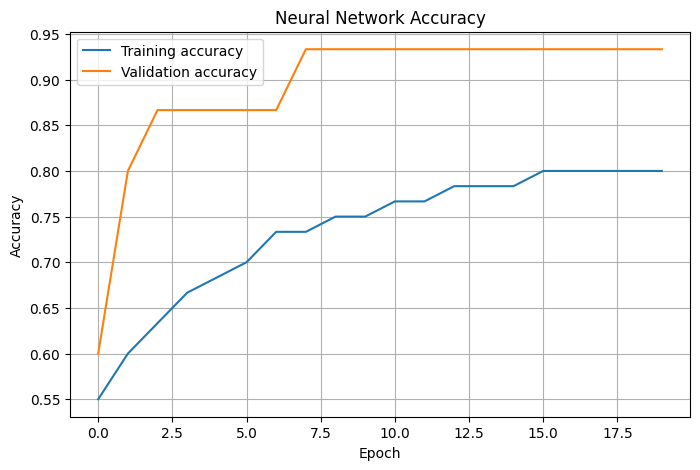

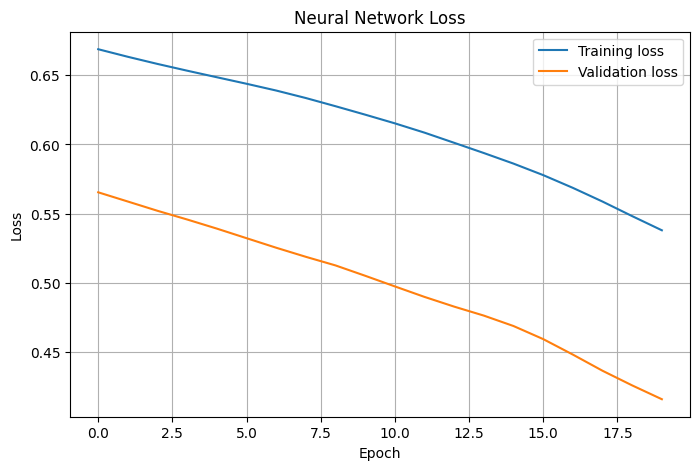

Test accuracy: 92.00%
Test loss: 0.4825


In [5]:
# Training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f'Test accuracy: {test_accuracy * 100:.2f}%')
print(f'Test loss: {test_loss:.4f}')

**Interpretation guide:** Review both graphs and the printed test metrics after running the notebook. If training accuracy improves while validation accuracy stops improving or falls, and training loss continues to fall while validation loss rises, the model may be overfitting. If both training and validation performance remain poor, it may be underfitting. Write your conclusion using the actual curves and values produced by your run; do not copy illustrative sample accuracies as measured results.

## Q5. New Predictions and Decision Tree Comparison (10 Marks)

**Aim:** Predict three new records and compare the neural network with a Decision Tree trained on the same train/test split.

The neural-network probability is classified as **Attack** when it is at least 0.50; otherwise it is classified as **Normal**. Probabilities close to 0.50 indicate greater uncertainty.

In [6]:
# Three new cyber-activity records
new_records = pd.DataFrame([
    {'failed_logins': 0, 'login_hour': 11, 'new_device': 0, 'data_transfer_mb': 35},
    {'failed_logins': 7, 'login_hour': 1, 'new_device': 1, 'data_transfer_mb': 250},
    {'failed_logins': 2, 'login_hour': 23, 'new_device': 1, 'data_transfer_mb': 850}
])

# Use the scaler fitted on training data
new_scaled = scaler.transform(new_records[features])
probabilities = model.predict(new_scaled, verbose=0).flatten()

results = new_records.copy()
results['nn_probability'] = probabilities.round(3)
results['nn_prediction'] = np.where(probabilities >= 0.50, 'Attack', 'Normal')

# Train Decision Tree using the same training split
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

results['tree_prediction'] = np.where(
    tree.predict(new_records[features]) == 1,
    'Attack',
    'Normal'
)

print(f'Neural-network accuracy: {test_accuracy * 100:.2f}%')
print(f'Decision-tree accuracy: {tree_accuracy * 100:.2f}%')
display(results)

Neural-network accuracy: 92.00%
Decision-tree accuracy: 88.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.266,Normal,Normal
1,7,1,1,250,0.649,Attack,Attack
2,2,23,1,850,0.286,Normal,Attack


### Comparison and conclusion

Compare the neural-network and Decision Tree test accuracies printed above. Also inspect whether both models agree on the three new records.

**Write your observations after running the notebook:**

1. Which model achieved higher test accuracy?
2. For which new records did the two models agree or disagree?
3. What might a disagreement or a probability close to 0.50 indicate?
4. Why might a simpler Decision Tree be selected if its performance is similar?  
   A Decision Tree may be preferred when similar performance is achieved because its decisions are generally easier to interpret and explain.

**Conclusion:** Complete this section using the actual results from your Colab run.

## Submission Checklist

- [ ] Q1 concept-matching table and explanation.
- [ ] Q2 dataset class counts and training/testing shapes.
- [ ] Q3 model summary and 20-epoch training output.
- [ ] Q4 accuracy and loss graphs.
- [ ] Q4 test accuracy and test loss.
- [ ] Q5 three new-record predictions.
- [ ] Neural Network and Decision Tree accuracy comparison.
- [ ] Written interpretation and conclusion.
- [ ] Completed notebook saved with outputs.

**Important:** Run all cells from top to bottom in Google Colab. Use the actual metrics generated by your run in your report; results may vary slightly.